# Sequence Classification using RNN/LSTM (Keras/TensorFlow)

This notebook demonstrates how to build and train Recurrent Neural Network (RNN) and Long Short-Term Memory (LSTM) models for sequence classification tasks using TensorFlow and Keras.

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

# Set random seed for reproducibility
tf.random.set_seed(42)
np.random.seed(42)

## 1. Dataset Preparation
We will generate synthetic sequence data. Let's create sequences of numbers where the task is to classify whether the sum of the sequence is greater than a certain threshold.

In [2]:
def generate_data(num_samples=1000, sequence_len=20):
    # Generate random sequences of floats between -1 and 1
    X = np.random.uniform(-1, 1, (num_samples, sequence_len, 1))
    # Label is 1 if the sum of the sequence is positive, else 0
    y = (np.sum(X, axis=1) > 0).astype(int)
    return X, y

# Generate train and validation data
X_train, y_train = generate_data(2000, 20)
X_val, y_val = generate_data(500, 20)

print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")

X_train shape: (2000, 20, 1)
y_train shape: (2000, 1)


## 2. Build and Train LSTM Model
LSTM networks are well-suited for classifying sequence data because of their ability to capture long-term dependencies.

In [3]:
model = keras.Sequential([
    layers.Input(shape=(20, 1)),
    layers.LSTM(32, return_sequences=False),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,897 (19.13 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=32
)

Epoch 1/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.7515 - loss: 0.5637 - val_accuracy: 0.8920 - val_loss: 0.4087
Epoch 2/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9290 - loss: 0.2697 - val_accuracy: 0.8980 - val_loss: 0.2255
Epoch 3/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9550 - loss: 0.1291 - val_accuracy: 0.9280 - val_loss: 0.1619
Epoch 4/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9680 - loss: 0.0896 - val_accuracy: 0.9300 - val_loss: 0.1343
Epoch 5/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9735 - loss: 0.0731 - val_accuracy: 0.9320 - val_loss: 0.1256
Epoch 6/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9785 - loss: 0.0643 - val_accuracy: 0.9480 - val_loss: 0.1086
Epoch 7/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9725 - loss: 0.0689 - val_accuracy: 0.9600 - val_loss: 0.0793
Epoch 8/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9790 - loss: 0.0561 - val_accuracy: 0.9560 - v

## 3. Visualize Results

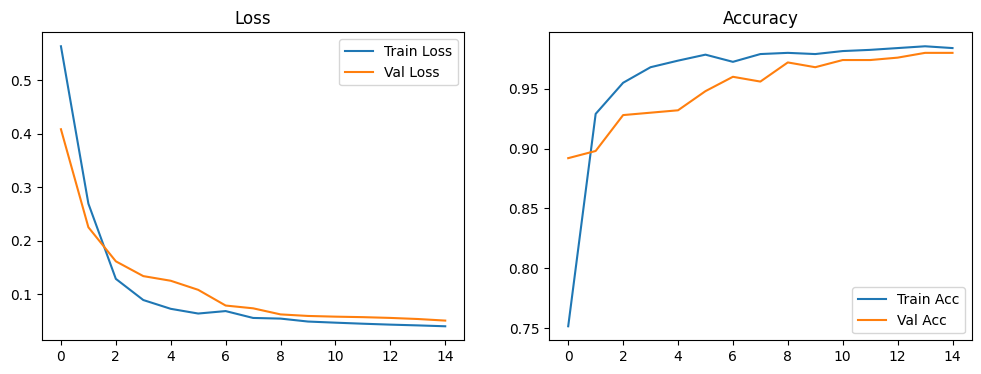

In [5]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title('Accuracy')
plt.legend()

plt.show()